In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.axes._axes import _log as matplotlib_axes_logger
from mpl_toolkits import mplot3d
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from matplotlib.colors import ListedColormap

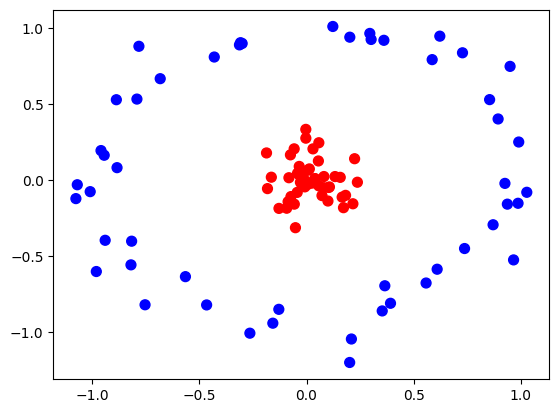

In [2]:
from sklearn.datasets import make_circles
X, y = make_circles(100, factor=.1, noise=.1)

plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='bwr')

plt.show()

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20)

In [4]:
classifier = SVC(kernel="linear")
classifier.fit(X_train, y_train.ravel())
y_pred = classifier.predict(X_test)

In [5]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test, y_pred)

0.45

In [6]:
zero_one_colourmap = ListedColormap(('blue', 'red'))
def plot_decision_boundary(X, y, clf):
    X_set, y_set = X, y
    X1, X2 = np.meshgrid(np.arange(start = X_set[:, 0].min() - 1, 
                                 stop = X_set[:, 0].max() + 1, 
                                 step = 0.01),
                       np.arange(start = X_set[:, 1].min() - 1, 
                                 stop = X_set[:, 1].max() + 1, 
                                 step = 0.01))
  
    plt.contourf(X1, X2, clf.predict(np.array([X1.ravel(), 
                                             X2.ravel()]).T).reshape(X1.shape),
               alpha = 0.75, 
               cmap = zero_one_colourmap)
    plt.xlim(X1.min(), X1.max())
    plt.ylim(X2.min(), X2.max())
    for i, j in enumerate(np.unique(y_set)):
        plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],
                c = (zero_one_colourmap)(i), label = j)
    plt.title('SVM Decision Boundary')
    plt.xlabel('X1')
    plt.ylabel('X2')
    plt.legend()
    return plt.show()

C:\Users\moham\AppData\Local\Temp\ipykernel_19624\3603277588.py:18: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],


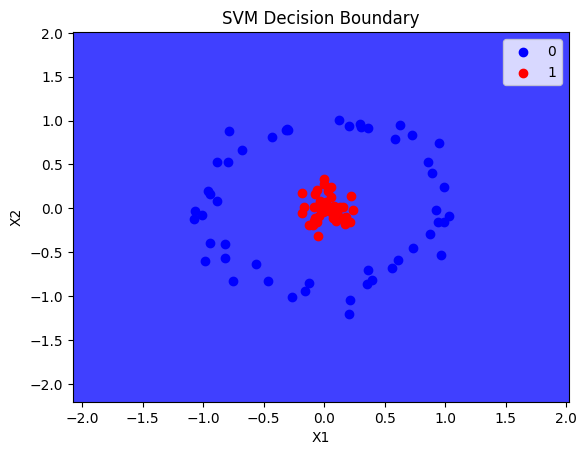

In [7]:
plot_decision_boundary(X, y, classifier)

In [8]:
def plot_3d_plot(X, y):
    r = np.exp(-(X ** 2).sum(1))
    ax = plt.subplot(projection='3d')
    ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=100, cmap='bwr')
    ax.set_xlabel('X1')
    ax.set_ylabel('X2')
    ax.set_zlabel('y')
    return ax

<Axes3D: xlabel='X1', ylabel='X2', zlabel='y'>

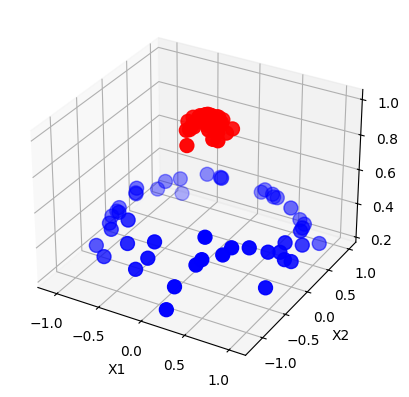

In [9]:
plot_3d_plot(X,y)

In [10]:
rbf_classifier = SVC(kernel="rbf")
rbf_classifier.fit(X_train, y_train)
y_pred = rbf_classifier.predict(X_test)

In [11]:
accuracy_score(y_test, y_pred)

1.0

C:\Users\moham\AppData\Local\Temp\ipykernel_19624\3603277588.py:18: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],


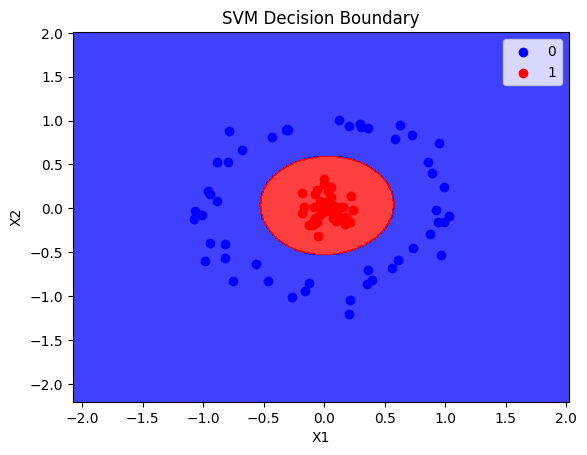

In [12]:
plot_decision_boundary(X, y, rbf_classifier)

In [13]:
poly_classifier = SVC(kernel="poly",degree=2)
poly_classifier.fit(X_train, y_train)
y_pred = poly_classifier.predict(X_test)

In [14]:
accuracy_score(y_test, y_pred)

1.0

C:\Users\moham\AppData\Local\Temp\ipykernel_19624\3603277588.py:18: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],


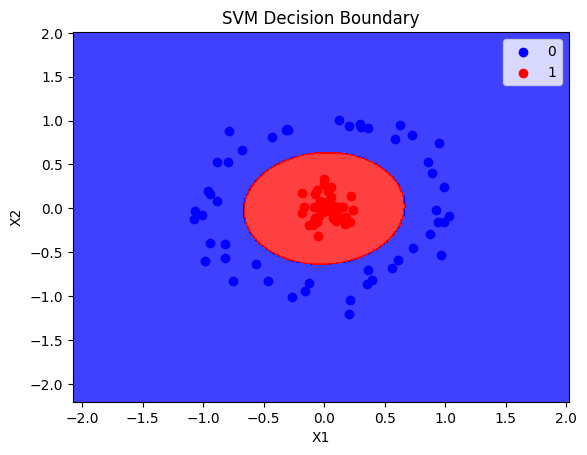

In [15]:
plot_decision_boundary(X, y, poly_classifier)

In [16]:
X

array([[-0.95995962,  0.19229231],
       [-0.08228605,  0.01355543],
       [-0.04216314,  0.04315222],
       [ 0.12281948,  1.00903332],
       [ 0.05756729, -0.04007683],
       [-0.0336798 ,  0.03303349],
       [ 0.22450472,  0.13873993],
       [ 0.20214003,  0.93853567],
       [ 0.05748251,  0.24382074],
       [-0.31324653,  0.88786455],
       [ 0.00882003, -0.02166073],
       [ 0.72844997,  0.83586421],
       [-0.00336798,  0.33183665],
       [ 0.35348894, -0.86311271],
       [-0.04353386, -0.08293012],
       [ 0.30165369,  0.92364963],
       [ 0.98789556, -0.15457054],
       [ 0.23750293, -0.01602304],
       [-0.15744439, -0.94378312],
       [ 0.62252269,  0.94527617],
       [-0.02861689, -0.01660358],
       [-0.88510687,  0.07979859],
       [ 0.29559939,  0.96332419],
       [ 0.58681834,  0.79086349],
       [-0.78295073,  0.87868028],
       [ 0.39216819, -0.81273985],
       [-1.07726952, -0.12389027],
       [-0.00531875, -0.01365629],
       [-0.03277995,

In [17]:
np.exp(-(X**2)).sum(1)

array([1.36161171, 1.99306815, 1.99636347, 1.34629188, 1.99508663,
       1.9977757 , 1.93178206, 1.37439378, 1.93898522, 1.36115245,
       1.99945313, 1.08547546, 1.89571927, 1.35728872, 1.99125279,
       1.33910211, 1.35322996, 1.94489707, 1.38587347, 1.08792994,
       1.99890577, 1.45049602, 1.31167592, 1.24368932, 1.00376829,
       1.3740162 , 1.29809485, 1.99978523, 1.99785341, 1.23830533,
       1.99940852, 1.29054235, 1.3623933 , 1.96779738, 1.31175606,
       1.26906264, 1.98256818, 1.99296976, 1.38417961, 1.14982624,
       1.94872834, 1.97203216, 1.99594861, 1.28798487, 1.97303447,
       1.90267302, 1.9985035 , 1.38946199, 1.19580599, 1.95687422,
       1.99112848, 1.9295905 , 1.24136526, 1.31450557, 1.99976838,
       1.38358029, 1.39491619, 1.99080578, 1.92771938, 1.98681099,
       1.9984684 , 1.39641828, 1.96392663, 1.30809152, 1.35412739,
       1.42316615, 1.46678979, 1.29322047, 1.99835345, 1.98641746,
       1.93749778, 1.31667433, 1.36235814, 1.98404332, 1.36064

In [18]:
X_new=np.exp(-(X**2))

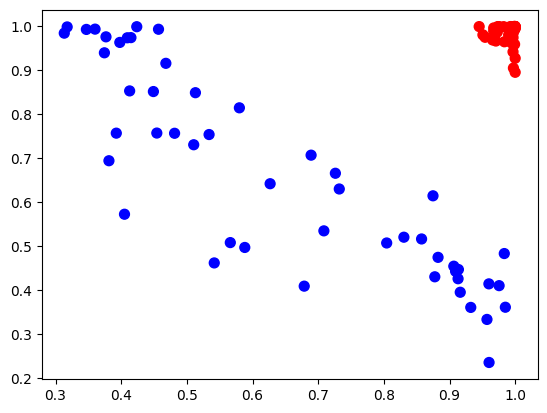

In [19]:
plt.scatter(X_new[:, 0], X_new[:, 1], c=y, s=50, cmap='bwr')